# Exploratory data analysis (PRD section 6)

**Data:** daily adjusted closes and volumes for ten NSE stocks and the NIFTY 50 price index (Yahoo Finance; local build in `data/processed/market_panel.csv`).
**Scope:** the **training period only** (1 Jan 2016 to 29 Dec 2023). Validation (2024 to May 2026) and the sealed test window (May to Nov 2026) are deliberately excluded so these findings can inform modelling choices without leaking later information.
**Caveat:** Yahoo prices are back-adjusted for later corporate actions, so price *levels* are not the prices quoted at the time; returns are reliable (see `reports/claude_dataset_audit_2026-11-14/CORPORATE_ACTION_AUDIT.md`). The 19 stale or phantom rows found by the audit fall after this period.

In [1]:
import os, sys, warnings
os.environ.setdefault("OMP_NUM_THREADS", "1")
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
pd.set_option("display.width", 160); pd.set_option("display.precision", 4)
PAL = ["#2B6CB0", "#C2571A", "#7B4FA6", "#2F8F6B"]; INK, GRID, PAPER = "#1C1B19", "#E4DFD5", "#FAF8F4"
plt.rcParams.update({"figure.facecolor": PAPER, "axes.facecolor": PAPER, "axes.edgecolor": "#8C867A", "axes.grid": True,
                     "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
                     "axes.titlesize": 10, "figure.dpi": 90, "axes.prop_cycle": plt.cycler(color=PAL)})
TRAIN_END = pd.Timestamp("2023-12-29")   # last feature date of the training partition
panel = pd.read_csv(ROOT / "data/processed/market_panel.csv", parse_dates=["Date"])
panel = panel[panel.Date <= TRAIN_END]   # validation and test periods are excluded
px = panel.pivot(index="Date", columns="Ticker", values="Adj Close")
vol = panel.pivot(index="Date", columns="Ticker", values="Volume")
r = np.log(px).diff().iloc[1:]
EQ = [c for c in px.columns if c != "^NSEI"]
short = lambda t: t.replace(".NS", "").replace("^NSEI", "NIFTY 50")
print(f"Training period: {px.index.min():%d %b %Y} to {px.index.max():%d %b %Y}; {len(px)} sessions; {len(EQ)} stocks + NIFTY 50")

Training period: 01 Jan 2016 to 29 Dec 2023; 1975 sessions; 10 stocks + NIFTY 50


## 1. Price trends with 50- and 200-session moving averages, and volume

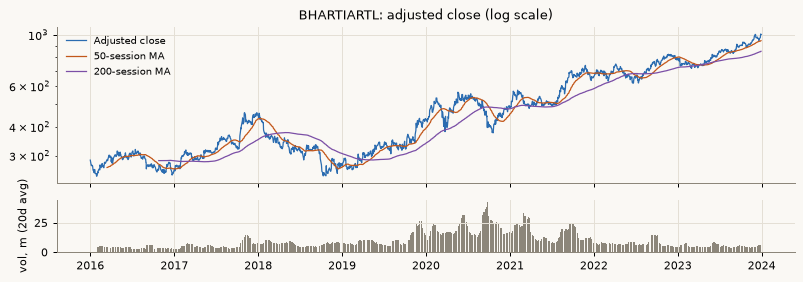

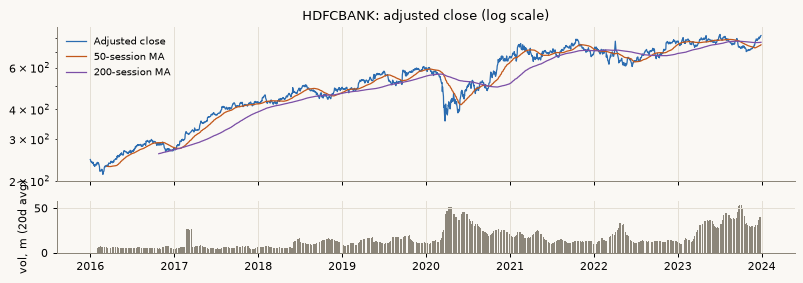

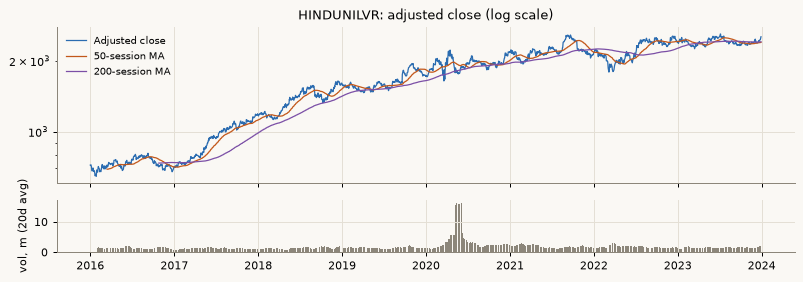

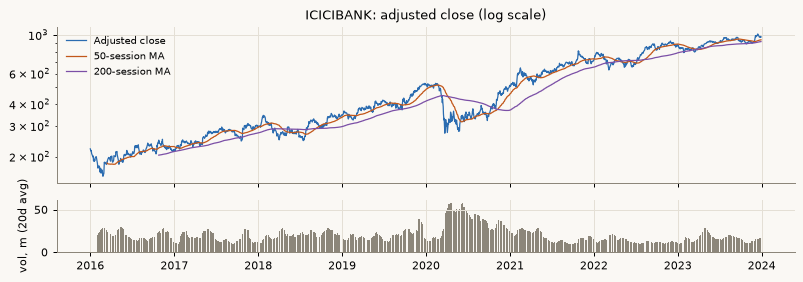

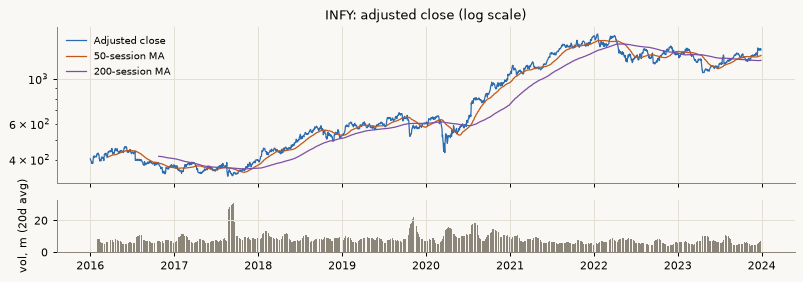

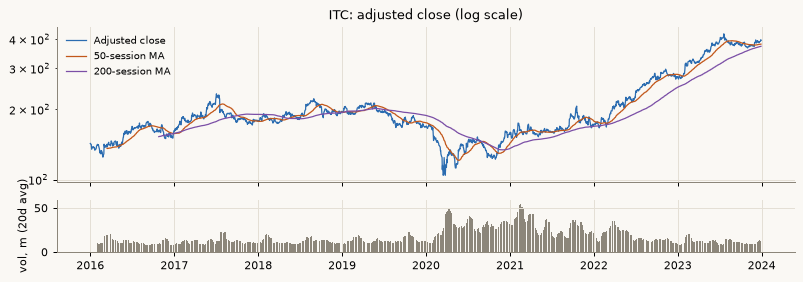

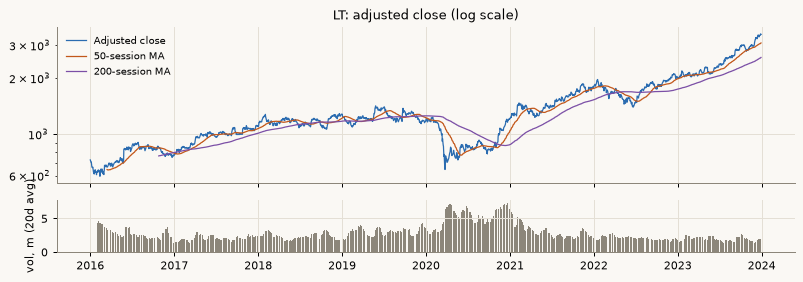

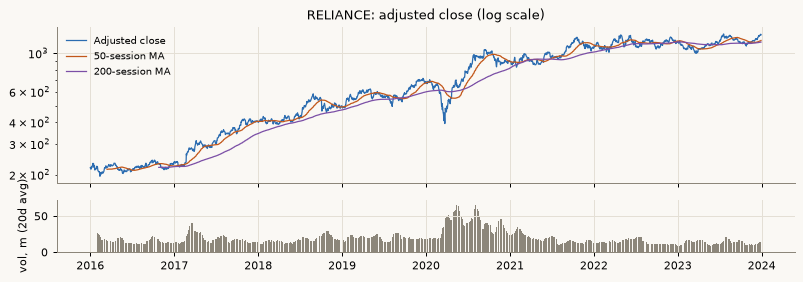

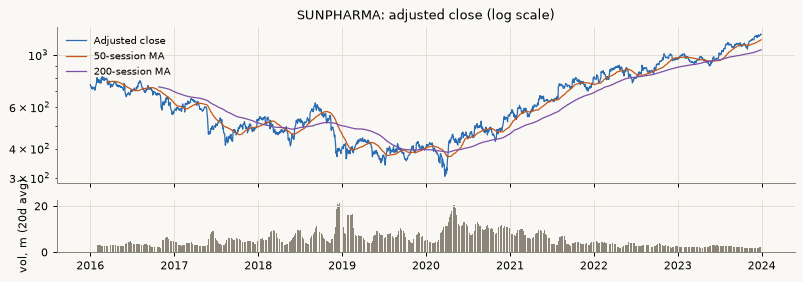

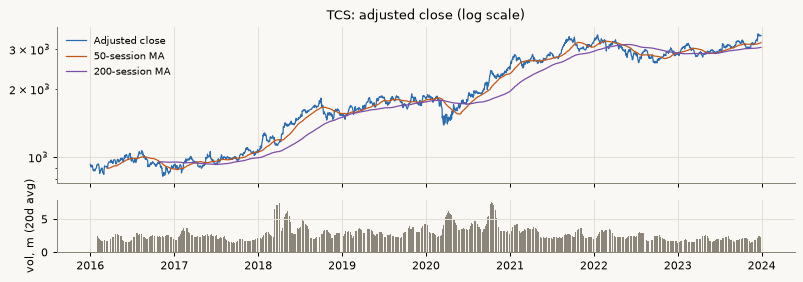

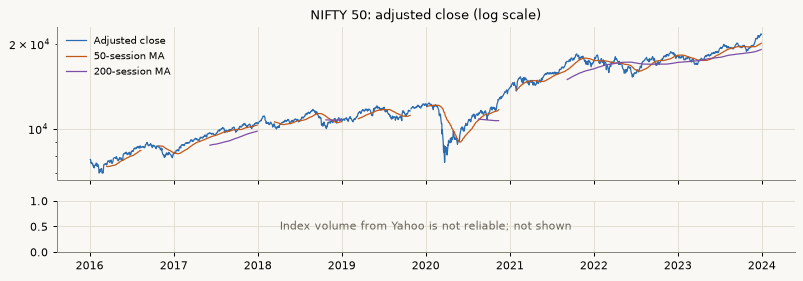

In [2]:
for t in px.columns:
    fig, (a, b) = plt.subplots(2, 1, figsize=(9, 3.2), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    s = px[t]; a.plot(s.index, s, color=PAL[0], lw=1, label="Adjusted close")
    a.plot(s.index, s.rolling(50).mean(), color=PAL[1], lw=1, label="50-session MA"); a.plot(s.index, s.rolling(200).mean(), color=PAL[2], lw=1, label="200-session MA")
    a.set_yscale("log"); a.set_title(f"{short(t)}: adjusted close (log scale)"); a.legend(loc="upper left", frameon=False, fontsize=8)
    if t == "^NSEI":
        b.text(0.5, 0.5, "Index volume from Yahoo is not reliable; not shown", ha="center", va="center", transform=b.transAxes, color="#6B665C")
    else:
        b.bar(vol.index, vol[t].rolling(20).mean() / 1e6, width=1.5, color="#8C867A"); b.set_ylabel("vol, m (20d avg)")
    plt.tight_layout(); plt.show()

**Finding.** Every series trends upward over 2016–2023 with a deep, synchronised fall in March 2020 and long stretches above and below the 200-session average. Levels differ by more than an order of magnitude between stocks.
**Consequence.** Raw prices are trending and scale-dependent, so they are a poor modelling target and a poor pooled feature. Models predict next-session *log returns*, and most features are ratios to moving averages rather than price levels.

## 2. Stationarity: Augmented Dickey-Fuller test on log price versus log return

In [3]:
from statsmodels.tsa.stattools import adfuller
adf = pd.DataFrame({short(t): {"ADF p-value, log price": adfuller(np.log(px[t].dropna()))[1],
                                "ADF p-value, log return": adfuller(r[t].dropna())[1]} for t in px}).T
adf["Price stationary at 5%?"] = adf["ADF p-value, log price"] < 0.05
adf["Return stationary at 5%?"] = adf["ADF p-value, log return"] < 0.05
display(adf.round(4))
print(f"Log prices: unit root NOT rejected for {(~adf['Price stationary at 5%?']).sum()} of {len(adf)} series. "
      f"Log returns: unit root rejected for {adf['Return stationary at 5%?'].sum()} of {len(adf)}.")

,"ADF p-value, log price","ADF p-value, log return",Price stationary at 5%?,Return stationary at 5%?
BHARTIARTL,0.9219,0.0,False,True
HDFCBANK,0.3589,0.0,False,True
HINDUNILVR,0.4938,0.0,False,True
ICICIBANK,0.8432,0.0,False,True
INFY,0.8666,0.0,False,True
ITC,0.9482,0.0,False,True
LT,0.9462,0.0,False,True
RELIANCE,0.6609,0.0,False,True
SUNPHARMA,0.9055,0.0,False,True
TCS,0.8269,0.0,False,True


Log prices: unit root NOT rejected for 11 of 11 series. Log returns: unit root rejected for 11 of 11.


**Finding.** For all eleven series the ADF test cannot reject a unit root in log prices (p between about 0.36 and 0.95), and strongly rejects it for log returns.
**Consequence.** This is the empirical justification for forecasting returns rather than prices, and for evaluating price forecasts against the naive random-walk baseline, which is the correct benchmark for a non-stationary price.

## 3. Return distributions: histograms with a normal overlay, QQ plots, skewness and kurtosis

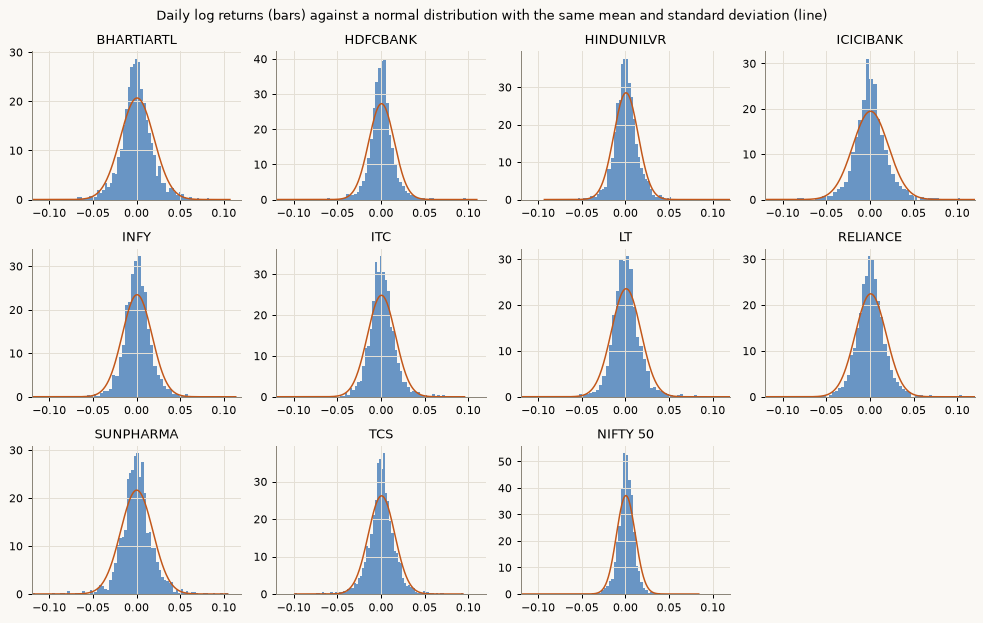

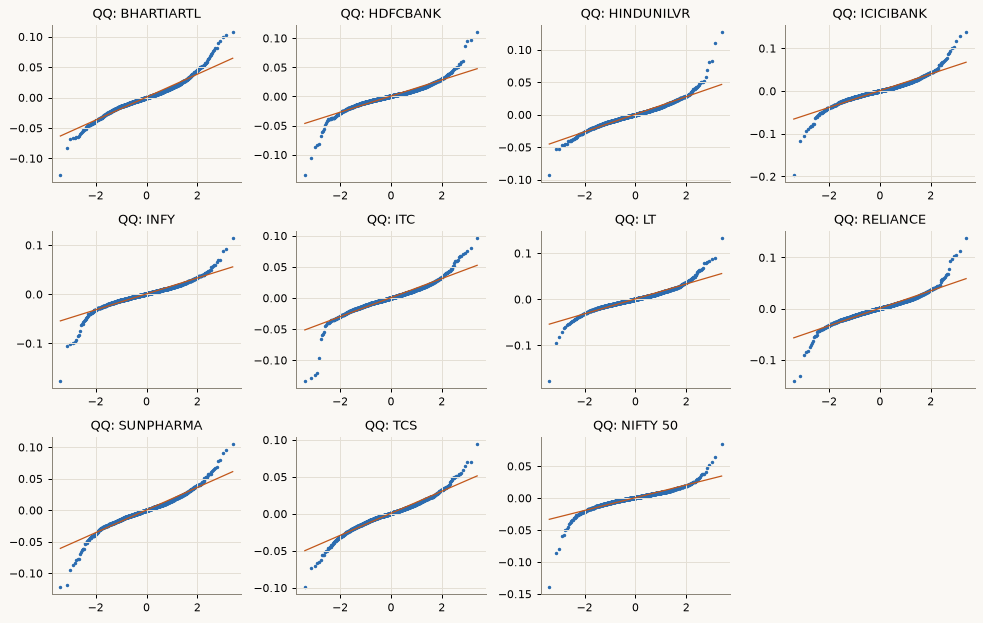

,mean (daily %),std (daily %),skewness,excess kurtosis,Jarque-Bera p
BHARTIARTL,0.0635,1.9297,0.3691,3.9083,0.0
HDFCBANK,0.0608,1.4631,-0.2587,11.4112,0.0
HINDUNILVR,0.0637,1.3994,0.7912,8.0940,0.0
ICICIBANK,0.0750,2.0497,-0.0911,9.3088,0.0
INFY,0.0626,1.7017,-0.8361,11.4456,0.0
ITC,0.0517,1.6077,-0.5859,10.4994,0.0
LT,0.0786,1.6933,-0.0133,10.9693,0.0
RELIANCE,0.0893,1.7790,0.1245,9.0318,0.0
SUNPHARMA,0.0251,1.8437,-0.1463,4.8346,0.0
TCS,0.0664,1.5226,-0.1148,3.8512,0.0


In [4]:
fig, axes = plt.subplots(3, 4, figsize=(11, 7)); axes = axes.ravel()
for ax, t in zip(axes, px.columns):
    x = r[t].dropna(); ax.hist(x, bins=80, density=True, color=PAL[0], alpha=0.7)
    g = np.linspace(x.min(), x.max(), 300); ax.plot(g, stats.norm.pdf(g, x.mean(), x.std()), color=PAL[1], lw=1.2)
    ax.set_title(short(t)); ax.set_xlim(-0.12, 0.12)
axes[-1].axis("off"); fig.suptitle("Daily log returns (bars) against a normal distribution with the same mean and standard deviation (line)", fontsize=10)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(3, 4, figsize=(11, 7)); axes = axes.ravel()
for ax, t in zip(axes, px.columns):
    (osm, osr), (sl, ic, _) = stats.probplot(r[t].dropna(), dist="norm")
    ax.scatter(osm, osr, s=3, color=PAL[0]); ax.plot(osm, sl * osm + ic, color=PAL[1], lw=1); ax.set_title(f"QQ: {short(t)}")
axes[-1].axis("off"); plt.tight_layout(); plt.show()
dist = pd.DataFrame({short(t): {"mean (daily %)": r[t].mean() * 100, "std (daily %)": r[t].std() * 100, "skewness": stats.skew(r[t].dropna()),
                                 "excess kurtosis": stats.kurtosis(r[t].dropna()), "Jarque-Bera p": stats.jarque_bera(r[t].dropna()).pvalue} for t in px}).T
display(dist.round(4))

**Finding.** Excess kurtosis ranges from about 4 to 23 (the index is highest, driven by March 2020) and the Jarque-Bera test rejects normality for every series with p effectively zero. Skewness is mixed in sign; the index is clearly negatively skewed. QQ plots bend away from the line in both tails.
**Consequence.** Risk must not assume normality: the dashboard reports historical (empirical) VaR and maximum drawdown alongside volatility, and the deep models use a Huber loss, which is less sensitive to extreme returns than squared error.

## 4. Correlation of daily returns (Pearson and Spearman)

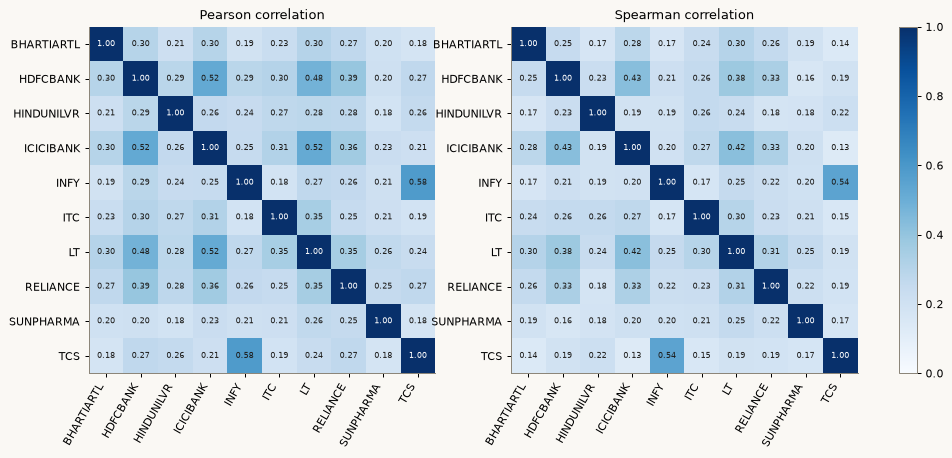

Average pairwise Pearson correlation 0.28 (range 0.18 to 0.58); highest pair: INFY-TCS.


,correlation with NIFTY 50
Ticker,
BHARTIARTL,0.45
HDFCBANK,0.74
HINDUNILVR,0.47
ICICIBANK,0.72
INFY,0.52
ITC,0.51
LT,0.68
RELIANCE,0.65
SUNPHARMA,0.39


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    c = r[EQ].corr(method=method); im = ax.imshow(c, vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(len(EQ)), [short(t) for t in EQ], rotation=60, ha="right"); ax.set_yticks(range(len(EQ)), [short(t) for t in EQ])
    for i in range(len(EQ)):
        for j in range(len(EQ)):
            ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="white" if c.iloc[i, j] > 0.6 else INK)
    ax.set_title(f"{method.title()} correlation"); ax.grid(False)
plt.colorbar(im, ax=axes, fraction=0.025); plt.show()
c = r[EQ].corr(); off = c.where(np.triu(np.ones(c.shape), 1).astype(bool)).stack()
print(f"Average pairwise Pearson correlation {off.mean():.2f} (range {off.min():.2f} to {off.max():.2f}); highest pair: {short(off.idxmax()[0])}-{short(off.idxmax()[1])}.")
display(r.corr()["^NSEI"].drop("^NSEI").rename(index=short).rename("correlation with NIFTY 50").to_frame().round(2))

**Finding.** Correlations are positive but moderate (average about 0.28), highest within sectors (Infosys–TCS about 0.58, HDFC Bank–ICICI Bank about 0.5). The banks and Larsen & Toubro move most with the index; Sun Pharma and Bharti Airtel least. Rank (Spearman) and linear (Pearson) correlations tell the same story.
**Consequence.** There is real diversification across the ten names, but sector pairs overlap. The optimiser therefore uses a shrunk (Ledoit-Wolf) covariance and a 30% per-stock cap to avoid concentrating in near-duplicates.

## 5. Volatility regimes and clustering, with India VIX

Correlation of NIFTY realised volatility with India VIX: 0.86


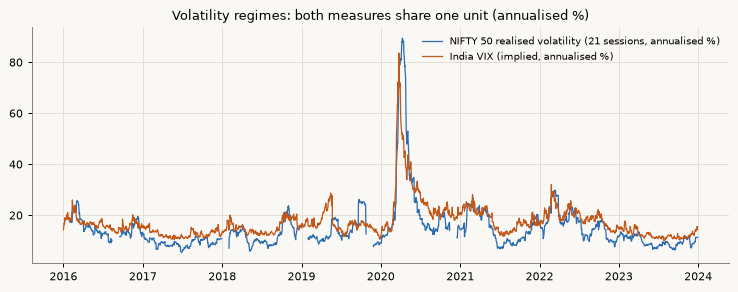

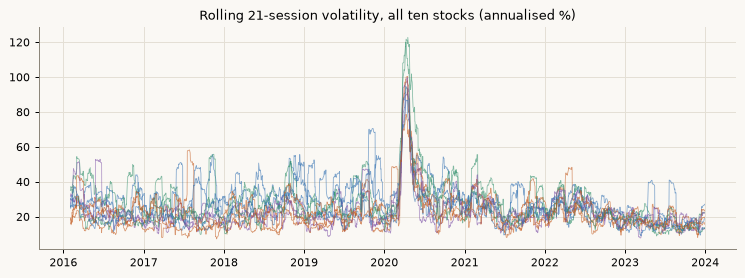

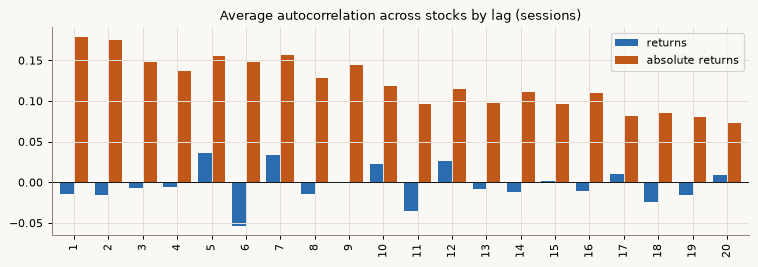

Mean lag-1 autocorrelation: returns -0.014, absolute returns +0.179


In [6]:
rv = r.rolling(21).std() * np.sqrt(252) * 100
vix_path = ROOT / "data/processed/market_context/market_context_panel.csv"
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(rv.index, rv["^NSEI"], color=PAL[0], lw=1, label="NIFTY 50 realised volatility (21 sessions, annualised %)")
if vix_path.exists():
    ctx = pd.read_csv(vix_path, parse_dates=["Date"]); vix = ctx[(ctx.Ticker == "^INDIAVIX") & (ctx.Date <= TRAIN_END)].set_index("Date").Close
    ax.plot(vix.index, vix, color=PAL[1], lw=1, label="India VIX (implied, annualised %)")
    j = pd.concat([rv["^NSEI"], vix], axis=1).dropna(); print(f"Correlation of NIFTY realised volatility with India VIX: {j.corr().iloc[0, 1]:.2f}")
else:
    print("India VIX not downloaded (scripts/download_market_context.py); realised volatility only.")
ax.legend(frameon=False, fontsize=8); ax.set_title("Volatility regimes: both measures share one unit (annualised %)"); plt.show()
fig, ax = plt.subplots(figsize=(10, 3.2))
for t in EQ: ax.plot(rv.index, rv[t], lw=0.6, alpha=0.6)
ax.set_title("Rolling 21-session volatility, all ten stocks (annualised %)"); plt.show()
lags = range(1, 21)
acf = pd.DataFrame({"returns": [r[EQ].apply(lambda s: s.autocorr(k)).mean() for k in lags],
                    "absolute returns": [r[EQ].abs().apply(lambda s: s.autocorr(k)).mean() for k in lags]}, index=lags)
ax = acf.plot.bar(figsize=(10, 3), color=[PAL[0], PAL[1]], width=0.8); ax.axhline(0, color=INK, lw=0.8)
ax.set_title("Average autocorrelation across stocks by lag (sessions)"); plt.show()
print(f"Mean lag-1 autocorrelation: returns {acf.loc[1, 'returns']:+.3f}, absolute returns {acf.loc[1, 'absolute returns']:+.3f}")

**Finding.** Volatility comes in regimes: calm 2017, stressed 2020, then a gradual decline. Realised NIFTY volatility tracks India VIX closely (correlation about 0.86). Returns themselves are almost uncorrelated from one day to the next (average lag-1 autocorrelation close to zero), but *absolute* returns are clearly autocorrelated over many lags: large moves cluster.
**Consequence.** The level of tomorrow's return is hard to predict from past returns, which is consistent with the models failing to beat the naive forecast, while the *size* of moves is predictable. Rolling volatility features are therefore included, and risk is measured over recent windows rather than full-history averages.

## 6. Seasonality: month and day of week, and an STL decomposition

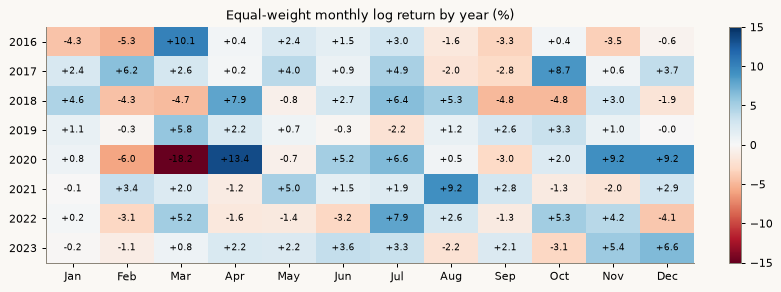

,mean (daily %),std (daily %),count,t-stat
Mon,-0.017,1.271,391,-0.262
Tue,0.163,0.959,391,3.369
Wed,0.071,0.859,400,1.654
Thu,0.021,0.982,399,0.433
Fri,0.078,0.930,391,1.653


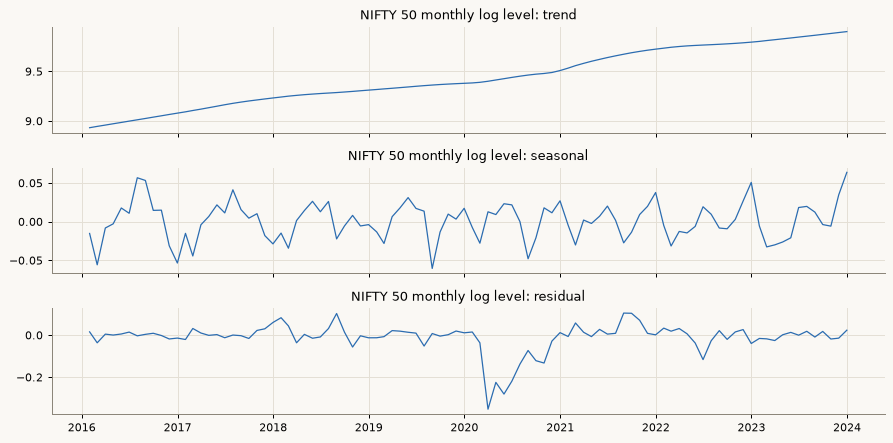

Seasonal component amplitude: 12.4% of index level; residual standard deviation 6.8%.


In [7]:
ew = r[EQ].mean(axis=1)   # equal-weight daily log return of the ten stocks
heat = ew.groupby([ew.index.year, ew.index.month]).sum().unstack() * 100
fig, ax = plt.subplots(figsize=(10, 3.4)); im = ax.imshow(heat, cmap="RdBu", vmin=-15, vmax=15, aspect="auto")
ax.set_xticks(range(12), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]); ax.set_yticks(range(len(heat)), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iloc[i, j]
        if pd.notna(v): ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=7)
ax.grid(False); ax.set_title("Equal-weight monthly log return by year (%)"); plt.colorbar(im, ax=ax, fraction=0.02); plt.show()
wd = ew[ew.index.dayofweek < 5]
dow = wd.groupby(wd.index.dayofweek).agg(["mean", "std", "count"]); dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri"]
dow["t-stat"] = dow["mean"] / (dow["std"] / np.sqrt(dow["count"])); dow["mean"] *= 100; dow["std"] *= 100
display(dow.rename(columns={"mean": "mean (daily %)", "std": "std (daily %)"}).round(3))
from statsmodels.tsa.seasonal import STL
m = np.log(px["^NSEI"]).resample("ME").last()
res = STL(m, period=12, robust=True).fit()
fig, axes = plt.subplots(3, 1, figsize=(10, 5), sharex=True)
for ax, (name, s) in zip(axes, [("trend", res.trend), ("seasonal", res.seasonal), ("residual", res.resid)]):
    ax.plot(s.index, s, color=PAL[0], lw=1); ax.set_title(f"NIFTY 50 monthly log level: {name}")
plt.tight_layout(); plt.show()
print(f"Seasonal component amplitude: {(res.seasonal.max() - res.seasonal.min()) * 100:.1f}% of index level; residual standard deviation {res.resid.std() * 100:.1f}%.")

**Finding.** No month is consistently positive or negative across years; the heatmap is dominated by year-specific events (2020). Among weekdays only Tuesday's mean is statistically distinguishable from zero on its own (t about 3.4), but with five days tested on one eight-year sample this is weak evidence and could be chance. STL assigns the index a seasonal swing of roughly 12% of its level, larger than the residual, yet the month-by-year heatmap shows that no month is consistently positive or negative; with only eight observations per calendar month, this pattern cannot be distinguished from a few large years (notably 2020).
**Consequence.** No calendar features were added. Any seasonal effect would need to be confirmed out of sample before it is used.

## Summary of decisions informed by this analysis

| Finding | Decision |
|---|---|
| Prices non-stationary, returns stationary (ADF) | Predict next-session log returns; benchmark against the naive random walk |
| Fat tails, non-normal returns | Empirical VaR and drawdown in risk reporting; Huber loss for deep models |
| Moderate, sector-clustered correlations | Ledoit-Wolf covariance and a 30% cap in optimisation |
| Volatility clustering; VIX tracks realised volatility | Rolling volatility features; recent-window risk measures |
| Little predictable autocorrelation in returns | Expect a hard-to-beat naive baseline (confirmed in validation) |
| No seasonality that is consistent across years | No calendar features |

All statistics above use the training period only.